Supervised Learning on Census Income - 10/25/2026 - addsmi1720

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
from datetime import datetime
from IPython.display import display, Markdown
import warnings
warnings.filterwarnings("ignore")

todays_date = datetime.now().strftime("%Y-%m-%d")
student_id = "addsmi1720"

# Load the Census Income dataset into a pandas DataFrame
data = pd.read_csv('census_income_dataset.csv')

display(Markdown("### Load and Explore the Dataset"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Get a concise summary of the DataFrame
print(data.info())

# Get descriptive statistics for the dataset
display(data.describe())

### Load and Explore the Dataset

Date: 2026-10-25

Student ID: addsmi1720

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       47879 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      47876 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48568 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB
None


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

display(Markdown("### Preprocess the Data"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Correct missing values: this dataset marks unknown values with '?', so convert those to NaN first
data = data.replace('?', np.nan)
print(f"Missing values before cleaning:\n{data.isnull().sum()[data.isnull().sum() > 0]}")

# Fill missing categorical values with the most common value in each column
for column in data.columns:
    if data[column].isnull().any():
        data[column] = data[column].fillna(data[column].mode()[0])
print(f"Missing values after cleaning: {data.isnull().sum().sum()}")

# Some income labels end with a period ('>50K.' and '<=50K.'), so remove it so every label matches '>50K' or '<=50K'
data['income'] = data['income'].str.strip().str.rstrip('.')

# Identify and remove any duplicate rows
print(f"Duplicate rows found: {data.duplicated().sum()}")
data = data.drop_duplicates()
print(f"Rows after removing duplicates: {data.shape[0]}")

# Convert the target variable (income) to binary
data['income'] = data['income'].apply(lambda x: 1 if x == '>50K' else 0)
print(f"Share of incomes above $50K: {data['income'].mean():.3f}")

# Perform one-hot encoding on categorical features
X = pd.get_dummies(data.drop(columns=['income']), dtype=int)
y = data['income']
print(f"Features after one-hot encoding: {X.shape[1]}")

# Split the dataset into training (70%) and testing (30%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Scale the numerical features (fit on training data only) so large values like fnlwgt don't dominate KNN's distance calculation
numerical_features = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
scaler = StandardScaler()
X_train[numerical_features] = scaler.fit_transform(X_train[numerical_features])
X_test[numerical_features] = scaler.transform(X_test[numerical_features])

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

### Preprocess the Data

Date: 2026-10-25

Student ID: addsmi1720

Missing values before cleaning:
workclass         2799
occupation        2809
native-country     857
dtype: int64
Missing values after cleaning: 0
Duplicate rows found: 53
Rows after removing duplicates: 48789
Share of incomes above $50K: 0.239
Features after one-hot encoding: 105
Training set size: 34152 samples
Test set size: 14637 samples


In [3]:
from sklearn.neighbors import KNeighborsClassifier

display(Markdown("### Implement K-Nearest Neighbors Algorithm"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Fit the KNN model on the training data
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

# Use the fitted model to predict the target values for the test data
y_pred = knn.predict(X_test)

print(f"Model: {knn}")
print(f"Predictions made: {len(y_pred)}")
display(pd.DataFrame({'Actual': y_test.values[:10], 'Predicted': y_pred[:10]}))

### Implement K-Nearest Neighbors Algorithm

Date: 2026-10-25

Student ID: addsmi1720

Model: KNeighborsClassifier()
Predictions made: 14637


,Actual,Predicted
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
5,1,0
6,1,0
7,0,0
8,1,0
9,1,1


In [4]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

display(Markdown("### Evaluate the Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['<=50K', '>50K']))

### Evaluate the Model

Date: 2026-10-25

Student ID: addsmi1720

Accuracy Score: 0.8312
Precision: 0.6834
Recall: 0.5923
F1 Score: 0.6346
Confusion Matrix:
[[10020   994]
 [ 1477  2146]]

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.87      0.91      0.89     11014
        >50K       0.68      0.59      0.63      3623

    accuracy                           0.83     14637
   macro avg       0.78      0.75      0.76     14637
weighted avg       0.82      0.83      0.83     14637



In [5]:
from sklearn.model_selection import GridSearchCV

display(Markdown("### Apply GridSearchCV for Hyperparameter Tuning"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Define the parameter grid
param_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

# Use GridSearchCV to find the best hyperparameters (n_jobs=-1 uses all CPU cores to speed it up)
grid_search = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation Score: {grid_search.best_score_:.4f}")

# Refit the model using the best parameters
tuned_knn = KNeighborsClassifier(**grid_search.best_params_)
tuned_knn.fit(X_train, y_train)
y_pred_tuned = tuned_knn.predict(X_test)
print(f"Tuned model: {tuned_knn}")

### Apply GridSearchCV for Hyperparameter Tuning

Date: 2026-10-25

Student ID: addsmi1720

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best Cross-Validation Score: 0.8418
Tuned model: KNeighborsClassifier(metric='euclidean', n_neighbors=9)


In [6]:
display(Markdown("### Evaluate the Tuned Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

print(f"Accuracy Score: {accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_tuned):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_tuned):.4f}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred_tuned)}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned, target_names=['<=50K', '>50K']))

### Evaluate the Tuned Model

Date: 2026-10-25

Student ID: addsmi1720

Accuracy Score: 0.8371
Precision: 0.7020
Recall: 0.5943
F1 Score: 0.6436
Confusion Matrix:
[[10100   914]
 [ 1470  2153]]

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.87      0.92      0.89     11014
        >50K       0.70      0.59      0.64      3623

    accuracy                           0.84     14637
   macro avg       0.79      0.76      0.77     14637
weighted avg       0.83      0.84      0.83     14637



### Visualize the Results

Date: 2026-10-25

Student ID: addsmi1720

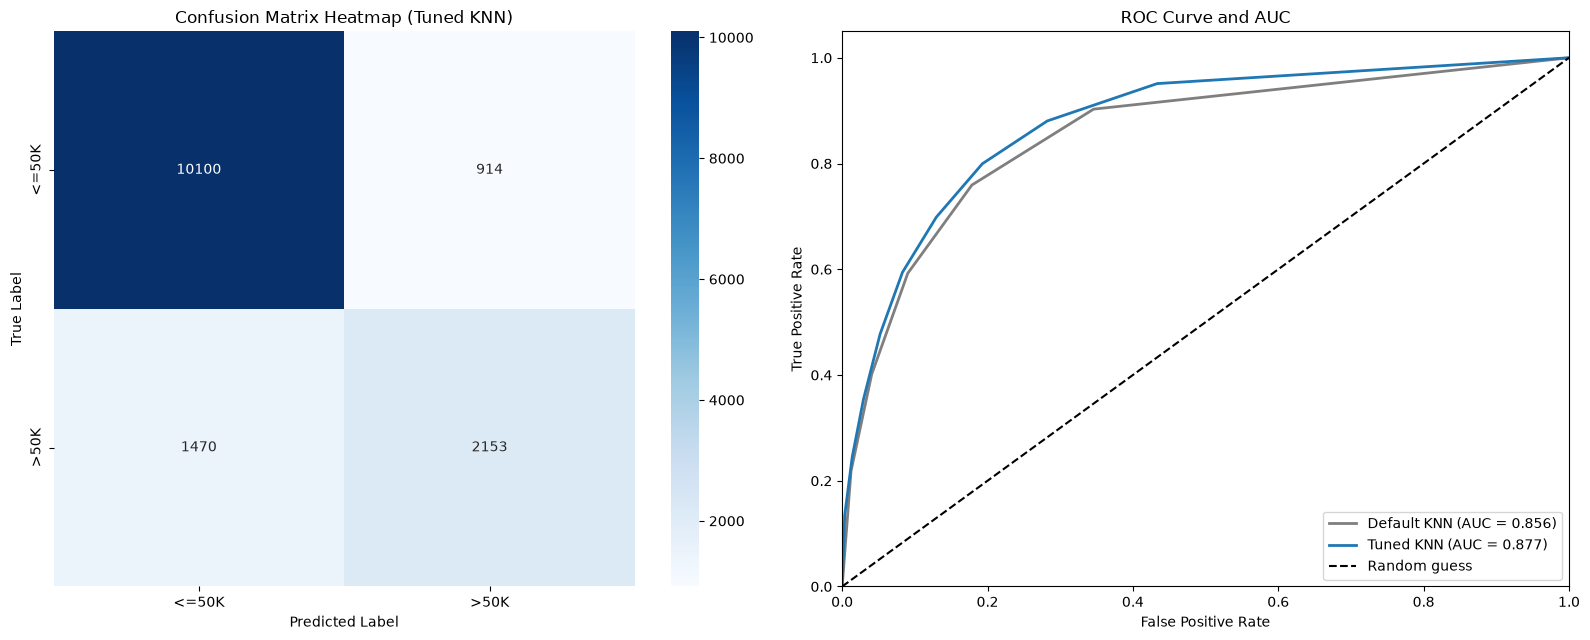

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score

display(Markdown("### Visualize the Results"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Confusion matrix heatmap for the tuned model
cm = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'])
axes[0].set_title('Confusion Matrix Heatmap (Tuned KNN)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC curves and AUC for the default and tuned models
for model, name, color in [(knn, 'Default KNN', 'tab:gray'), (tuned_knn, 'Tuned KNN', 'tab:blue')]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    axes[1].plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC = {auc:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random guess')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve and AUC')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

## Analyze and Interpret

**1. How well does the K-Nearest Neighbors model perform on the Census Income dataset before and after hyperparameter tuning?**

Before tuning, the default KNN model (5 neighbors) reached 83.11% accuracy on the 14,637 test records, with a precision of 0.683, recall of 0.592, F1 score of 0.635, and an AUC of 0.856 for the >50K class. After tuning, accuracy rose to 83.71%, precision to 0.702, recall to 0.594, F1 to 0.644, and AUC to 0.877. Both versions do well on the <=50K group, catching about 92% of them, but they struggle with high earners. The tuned model still misses 1,470 of the 3,623 people who actually earn over $50K, which is a recall of only 59%. Part of that is the class imbalance: only about 24% of people in the data earn over $50K, so a model that predicted <=50K for everyone would already score about 75% accuracy. That makes precision, recall, F1, and AUC more meaningful than accuracy here. One preprocessing step mattered more than tuning: KNN is based on distance, so I scaled the numeric columns before training. Without scaling, the fnlwgt column (values in the hundreds of thousands) dominated the distance and accuracy dropped to about 77%.

**2. Which hyperparameters were selected as optimal by GridSearchCV, and how did they affect the model performance?**

GridSearchCV selected 9 neighbors, uniform weights, and the euclidean distance metric, with a cross-validation accuracy of 84.18%. Using 9 neighbors instead of the default 5 lets more neighbors vote on each prediction, which smooths out noise from individual records. That cut false positives from 995 to 914, raised precision from 0.683 to 0.702, and raised AUC from 0.856 to 0.877, while recall barely changed. Uniform weights beat distance weights at every value of k, which suggests that letting the very closest neighbor dominate the vote caused the model to overfit to noise. Euclidean and minkowski produced identical scores because minkowski uses p = 2 by default, which is the euclidean formula, and manhattan scored slightly lower. Since k = 9 was the largest value in the grid and accuracy was still rising, testing larger values like 11 to 21 would be a sensible next step.
